# Forecasting Baselines

## 1. Load and Validate Hourly Data

Establish simple, reproducible benchmarks for forecasting
electricity demand over the next 24 hours.

Initial approach:
- Use chronological data splits.
- Preserve missing observations.
- Evaluate against daily and weekly seasonal-naive forecasts.
- Prevent future information from entering predictions.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_parquet(
    PROJECT_ROOT / "data/processed/hourly_power.parquet"
)

df = df.sort_values("timestamp").set_index("timestamp")

df.head()

,mean_power_kw,valid_minutes
timestamp,,
2006-12-16 17:00:00,4.222889,36
2006-12-16 18:00:00,3.632200,60
2006-12-16 19:00:00,3.400233,60
2006-12-16 20:00:00,3.268567,60
2006-12-16 21:00:00,3.056467,60


In [2]:
# Preserve the full hourly timeline.
power = df["mean_power_kw"].where(
    df["valid_minutes"] == 60
)

print("Total hours:", len(power))
print("Usable hours:", power.notna().sum())
print("Unavailable hours:", power.isna().sum())

Total hours: 34589
Usable hours: 34085
Unavailable hours: 504


## 2. Naive and Seasonal-Naive Forecasts

In [14]:
baseline_df = pd.DataFrame({
    "actual": power,
    "persistence": power.shift(1),
    "daily_naive": power.shift(24),
    "weekly_naive": power.shift(168),
})

baseline_df.head(30)

,actual,persistence,daily_naive,weekly_naive
timestamp,,,,
2006-12-16 17:00:00,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,3.632200,NaN,NaN
2006-12-16 20:00:00,3.268567,3.400233,NaN,NaN
2006-12-16 21:00:00,3.056467,3.268567,NaN,NaN
2006-12-16 22:00:00,2.200133,3.056467,NaN,NaN
2006-12-16 23:00:00,2.061600,2.200133,NaN,NaN
2006-12-17 00:00:00,1.882467,2.061600,NaN,NaN
2006-12-17 01:00:00,3.349400,1.882467,NaN,NaN


In [4]:
print("Total hourly observations:", len(baseline_df))

print(
    "Valid daily baseline comparisons:",
    baseline_df[["actual", "daily_naive"]].dropna().shape[0]
)

print(
    "Valid weekly baseline comparisons:",
    baseline_df[["actual", "weekly_naive"]].dropna().shape[0]
)

print(
    "Valid comparisons for both baselines:",
    baseline_df.dropna().shape[0]
)

Total hourly observations: 34589
Valid daily baseline comparisons: 33833
Valid weekly baseline comparisons: 33417
Valid comparisons for both baselines: 33130


In [5]:
train = baseline_df.loc[: "2008-12-31 23:00"]
val = baseline_df.loc["2009-01-01":"2009-12-31 23:00"]
test = baseline_df.loc["2010-01-01":]

print("Training:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Training: 17911
Validation: 8760
Test: 7918


In [6]:
for name, split in [
    ("Train", train),
    ("Validation", val),
    ("Test", test),
]:
    print(
        name,
        "| Start:", split.index.min(),
        "| End:", split.index.max(),
        "| Rows:", len(split),
    )

Train | Start: 2006-12-16 17:00:00 | End: 2008-12-31 23:00:00 | Rows: 17911
Validation | Start: 2009-01-01 00:00:00 | End: 2009-12-31 23:00:00 | Rows: 8760
Test | Start: 2010-01-01 00:00:00 | End: 2010-11-26 21:00:00 | Rows: 7918


## 3. Baseline Evaluation

Compare daily and weekly seasonal-naive forecasts
using MAE and RMSE on identical validation timestamps.

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compare both baselines on the same valid timestamps
val_clean = val.dropna(
    subset=["actual", "persistence", "daily_naive", "weekly_naive"]
)

results = []

for model in ["persistence", "daily_naive", "weekly_naive"]:
    mae = mean_absolute_error(
        val_clean["actual"],
        val_clean[model]
    )

    rmse = np.sqrt(
        mean_squared_error(
            val_clean["actual"],
            val_clean[model]
        )
    )

    results.append({
        "model": model,
        "MAE_kW": mae,
        "RMSE_kW": rmse
    })

results_df = pd.DataFrame(results)
results_df

,model,MAE_kW,RMSE_kW
0,persistence,0.430366,0.656844
1,daily_naive,0.607710,0.897336
2,weekly_naive,0.564554,0.843648


## 4. Visualize Baseline Predictions

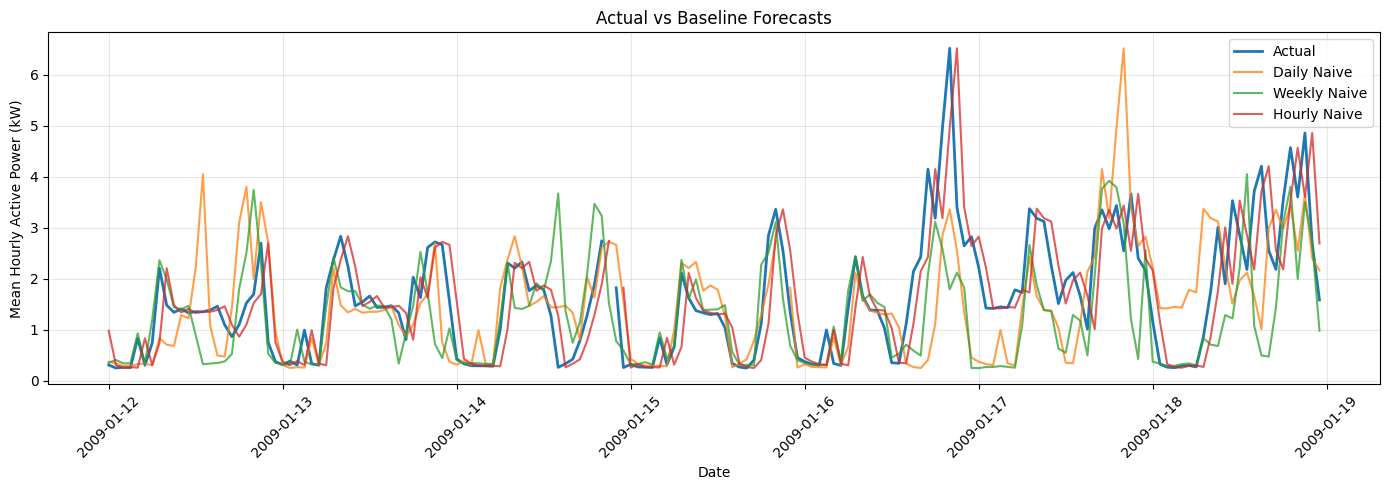

In [24]:
# Select one week of validation data
sample = val.loc["2009-01-12":"2009-01-18"]

plt.figure(figsize=(14, 5))

plt.plot(
    sample.index,
    sample["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    sample.index,
    sample["daily_naive"],
    label="Daily Naive",
    alpha=0.75
)

plt.plot(
    sample.index,
    sample["weekly_naive"],
    label="Weekly Naive",
    alpha=0.75
)

plt.plot(
    sample.index,
    sample["persistence"],
    label="Hourly Naive",
    alpha=0.75
)

plt.title("Actual vs Baseline Forecasts")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

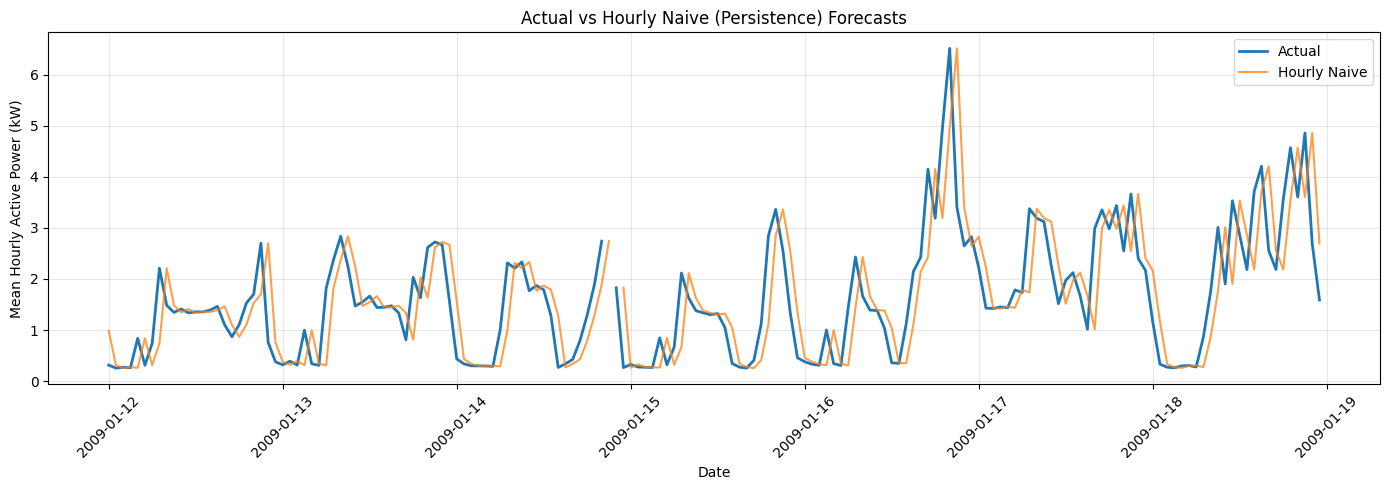

In [22]:
# One week of Actual vs Hourly Naïve (Persistence)
sample = val.loc["2009-01-12":"2009-01-18"]

plt.figure(figsize=(14, 5))

plt.plot(
    sample.index,
    sample["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    sample.index,
    sample["persistence"],
    label="Hourly Naive",
    alpha=0.75
)

plt.title("Actual vs Hourly Naive (Persistence) Forecasts")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Baseline Forecast Observations

- Both daily and weekly seasonal-naive models capture recurring
  daily electricity consumption patterns.
- Both struggle with sudden, unusually high consumption peaks.
- The January 16 spike (~6.5 kW) is substantially underestimated
  by both baselines.
- The daily baseline repeats this spike on January 17,
  creating a large overprediction.
- Weekly seasonal naive performs better overall on validation,
  suggesting that weekly consumption routines contain useful
  forecasting information.

**Implication:** Future models should be evaluated not only
on average forecasting error, but also on their ability to
anticipate high-demand periods.

## 5. Forecasting Error by Hour of Day

Investigate whether daily and weekly seasonal-naive models
make larger forecasting errors during particular hours.

In [26]:
# Use the same clean validation data from Step 10
hourly_errors = val_clean.copy()

# Extract hour of day from the timestamp index
hourly_errors["hour"] = hourly_errors.index.hour

# Calculate absolute forecasting errors

hourly_errors["persistence_error"] = (
    hourly_errors["actual"] - hourly_errors["persistence"]
).abs()

hourly_errors["daily_error"] = (
    hourly_errors["actual"] - hourly_errors["daily_naive"]
).abs()

hourly_errors["weekly_error"] = (
    hourly_errors["actual"] - hourly_errors["weekly_naive"]
).abs()

# Average the errors for each hour
error_by_hour = hourly_errors.groupby("hour")[
    ["persistence_error", "daily_error", "weekly_error"]
].mean()

error_by_hour.head()

,persistence_error,daily_error,weekly_error
hour,,,
0,0.341183,0.408798,0.343522
1,0.175768,0.302714,0.293189
2,0.138106,0.243054,0.231446
3,0.126390,0.217646,0.222069
4,0.160860,0.227625,0.248950


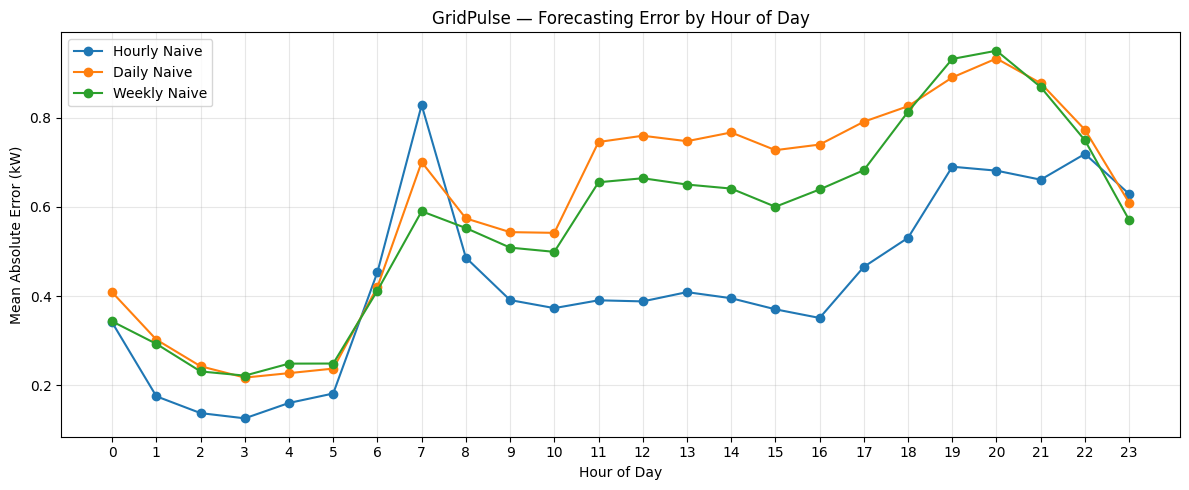

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    error_by_hour.index,
    error_by_hour["persistence_error"],
    marker="o",
    label="Hourly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["daily_error"],
    marker="o",
    label="Daily Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["weekly_error"],
    marker="o",
    label="Weekly Naive"
)

plt.title("GridPulse — Forecasting Error by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### ### Forecast Error by Hour — Findings

- Hourly naïve (persistence) achieves the lowest forecasting error during most hours of the day.
- All three baselines perform best during overnight hours, with persistence achieving its lowest MAE around 3 AM.
- Persistence experiences a pronounced error spike at 7 AM, where both daily and weekly seasonal-naïve baselines perform better.
- Weekly naïve outperforms daily naïve throughout much of the daytime, suggesting that weekly consumption patterns provide useful forecasting information.
- Evening demand remains challenging for all three baselines, although persistence maintains lower errors than the seasonal baselines during most evening hours.

**Interpretation:** Recent electricity consumption is a strong predictor of next-hour demand during stable periods. However, recurring daily and weekly patterns may provide additional predictive value during rapid demand transitions, particularly the morning peak.

**Modeling implication:** Combine recent consumption (`lag_1`), daily consumption (`lag_24`), weekly consumption (`lag_168`), and calendar features in subsequent machine learning models. Evaluate whether these models can reduce forecasting errors during morning and evening demand peaks.

## 6. Forecasting Error by Season

Compare daily and weekly seasonal-naive forecasting
performance across winter, spring, summer, and fall.

In [28]:
seasonal_errors = val_clean.copy()

# Extract the month from the timestamp
seasonal_errors["month"] = seasonal_errors.index.month

# Map each month to a season
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

seasonal_errors["season"] = (
    seasonal_errors["month"].map(season_map)
)

# Calculate absolute forecasting errors
seasonal_errors["persistence_error"] = (
    seasonal_errors["actual"] -
    seasonal_errors["persistence"]
).abs()

seasonal_errors["daily_error"] = (
    seasonal_errors["actual"] -
    seasonal_errors["daily_naive"]
).abs()

seasonal_errors["weekly_error"] = (
    seasonal_errors["actual"] -
    seasonal_errors["weekly_naive"]
).abs()

# Average error by season
error_by_season = seasonal_errors.groupby("season")[
    ["persistence_error", "daily_error", "weekly_error"]
].mean()

# Arrange seasons chronologically
error_by_season = error_by_season.reindex(
    ["Winter", "Spring", "Summer", "Fall"]
)

error_by_season

,persistence_error,daily_error,weekly_error
season,,,
Winter,0.492822,0.769925,0.725537
Spring,0.442234,0.591989,0.567009
Summer,0.314148,0.430638,0.445704
Fall,0.465158,0.628754,0.514186


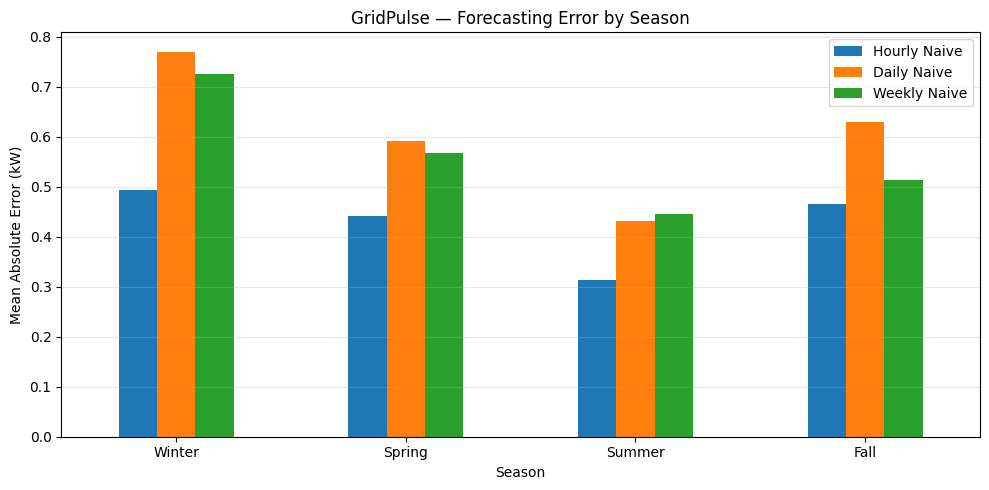

In [29]:
ax = error_by_season.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("GridPulse — Forecasting Error by Season")
plt.xlabel("Season")
plt.ylabel("Mean Absolute Error (kW)")
plt.legend(["Hourly Naive", "Daily Naive", "Weekly Naive"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal Forecast Error — Findings

- Hourly naïve (persistence) achieves the lowest forecasting error across all four seasons.
- Winter has the highest forecasting errors for all three baselines.
- Summer has the lowest forecasting errors, suggesting that electricity demand may be more predictable during this period.
- Weekly naïve outperforms daily naïve in winter, spring, and fall, while daily naïve performs slightly better in summer.
- The performance gap between hourly and weekly naïve is smallest during fall.

**Interpretation:** Recent electricity consumption provides strong predictive information across all seasons. However, the relative performance of daily and weekly baselines varies by season, suggesting that recurring consumption patterns may provide additional value under different seasonal conditions.

**Modeling implication:** Incorporate recent demand, daily and weekly historical demand, and calendar features into subsequent machine learning models. Evaluate whether these models can improve upon persistence across all seasons, particularly during high-error winter periods.

**Limitation:** These findings are based on the 2009 validation period for a single household. Seasonal differences may reflect consumption levels, household behavior, weather, or other factors not directly measured in the dataset.

## 7. Forecasting Error by Weekday vs. Weekend

Compare baseline forecasting performance across weekdays
and weekends to investigate whether differences in household
routines influence forecasting accuracy.

In particular, examine whether the 7 AM forecasting error
spike observed in the hourly naive baseline is more
pronounced on weekdays.

In [30]:
weekday_errors = val_clean.copy()

# Extract hour of day
weekday_errors["hour"] = weekday_errors.index.hour

# Extract day of week
weekday_errors["day_of_week"] = (
    weekday_errors.index.dayofweek
)

# Identify weekends
weekday_errors["is_weekend"] = (
    weekday_errors["day_of_week"] >= 5
)

weekday_errors.head()

,actual,persistence,daily_naive,weekly_naive,hour,day_of_week,is_weekend
timestamp,,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0,3,False
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,1,3,False
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,2,3,False
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,3,3,False
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,4,3,False


### Calculate forecasting errors

In [31]:
weekday_errors["persistence_error"] = (
    weekday_errors["actual"] -
    weekday_errors["persistence"]
).abs()

weekday_errors["daily_error"] = (
    weekday_errors["actual"] -
    weekday_errors["daily_naive"]
).abs()

weekday_errors["weekly_error"] = (
    weekday_errors["actual"] -
    weekday_errors["weekly_naive"]
).abs()

### Group by weekday/weekend AND hour

In [32]:
error_by_day_type = weekday_errors.groupby(
    ["is_weekend", "hour"]
)[
    ["persistence_error", "daily_error", "weekly_error"]
].mean()

error_by_day_type

persistence_error  daily_error  weekly_error
is_weekend hour                                              
False      0              0.328540     0.349122      0.257625
           1              0.140525     0.250741      0.201697
           2              0.116297     0.216020      0.179466
           3              0.121075     0.191321      0.186923
           4              0.163729     0.211516      0.229618
           5              0.183733     0.215345      0.214301
           6              0.546018     0.420768      0.455182
           7              0.911277     0.666242      0.583746
           8              0.494340     0.549760      0.521228
           9              0.347865     0.544238      0.459697
           10             0.315616     0.535114      0.455781
           11             0.301207     0.650508      0.531244
           12             0.316615     0.718617      0.591330
           13             0.330539     0.709370      0.608581
           14             0.301139     0.729773      0.567953
           15             0.328641     0.630887      0.515369
           16             0.276475     0.660265      0.508287
           17             0.381941     0.697744      0.509940
           18             0.483735     0.756239      0.701619
           19             0.722524     0.880186      0.885508
           20             0.684704     0.893406      0.908227
           21             0.679830     0.792496      0.773928
           22             0.709945     0.689332      0.667962
           23             0.645449     0.480499      0.505670
True       0              0.373803     0.562761      0.565136
           1              0.266694     0.436804      0.529238
           2              0.194374     0.312802      0.365553
           3              0.140104     0.285563      0.312745
           4              0.153544     0.268704      0.298245
           5              0.177659     0.294788      0.337582
           6              0.218831     0.420798      0.303714
           7              0.615654     0.787247      0.606620
           8              0.466013     0.635404      0.631238
           9              0.505370     0.541289      0.637697
           10             0.521137     0.559078      0.610867
           11             0.619968     0.988073      0.972226
           12             0.572542     0.863928      0.851198
           13             0.610866     0.844066      0.756435
           14             0.637675     0.861510      0.828695
           15             0.480117     0.978205      0.821952
           16             0.548514     0.948721      0.984014
           17             0.687947     1.037698      1.139828
           18             0.656787     1.011062      1.111767
           19             0.604850     0.915205      1.050928
           20             0.671931     1.031805      1.056020
           21             0.613034     1.090822      1.106819
           22             0.740961     0.988608      0.959129
           23             0.585849     0.942422      0.738535

### Separate the two groups

In [33]:
weekday_profile = error_by_day_type.loc[False]

weekend_profile = error_by_day_type.loc[True]

weekday_profile.head()

,persistence_error,daily_error,weekly_error
hour,,,
0,0.328540,0.349122,0.257625
1,0.140525,0.250741,0.201697
2,0.116297,0.216020,0.179466
3,0.121075,0.191321,0.186923
4,0.163729,0.211516,0.229618


### Visualize Weekday vs. Weekend Forecasting Errors

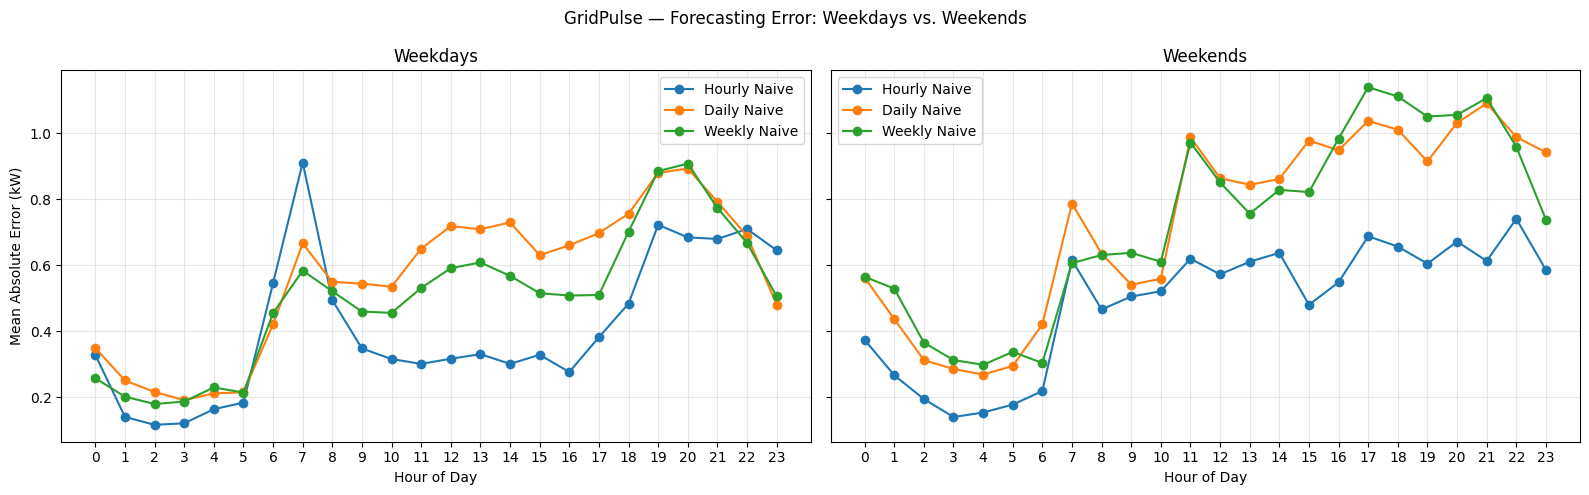

In [34]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, profile, title in [
    (axes[0], weekday_profile, "Weekdays"),
    (axes[1], weekend_profile, "Weekends")
]:
    ax.plot(
        profile.index,
        profile["persistence_error"],
        marker="o",
        label="Hourly Naive"
    )

    ax.plot(
        profile.index,
        profile["daily_error"],
        marker="o",
        label="Daily Naive"
    )

    ax.plot(
        profile.index,
        profile["weekly_error"],
        marker="o",
        label="Weekly Naive"
    )

    ax.set_title(title)
    ax.set_xlabel("Hour of Day")
    ax.set_xticks(range(24))
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Mean Absolute Error (kW)")

fig.suptitle(
    "GridPulse — Forecasting Error: Weekdays vs. Weekends"
)

plt.tight_layout()
plt.show()

### Weekday vs. Weekend Forecast Error — Findings

- Hourly naïve (persistence) achieves the lowest forecasting error during most hours on both weekdays and weekends.
- Persistence exhibits a pronounced error spike at 7 AM on weekdays, reaching approximately 0.91 kW MAE.
- Weekly naïve performs best at 7 AM on weekdays, with an MAE of approximately 0.58 kW.
- The 7 AM persistence error spike is less pronounced on weekends, supporting the hypothesis that forecasting difficulty differs between weekday and weekend mornings.
- Weekend forecasting errors are generally higher during daytime hours, particularly for the daily and weekly seasonal-naïve baselines.
- Persistence maintains a substantial advantage over both seasonal baselines throughout much of the weekend afternoon and evening.

**Interpretation:** Recent consumption is a strong predictor of next-hour electricity demand. However, persistence struggles during rapid demand transitions, particularly weekday mornings. Daily and weekly historical patterns may provide complementary predictive information during these periods.

**Modeling implication:** Include `lag_1`, `lag_24`, `lag_168`, `hour`, `day_of_week`, and `is_weekend` in subsequent machine learning models. Investigate interactions between hour of day and weekend status to determine whether models can better capture distinct weekday and weekend demand patterns.

**Limitation:** These findings are based on a single household's 2009 validation data. Household activities and the causes of consumption changes cannot be directly verified.